# Phishing Email Detection System
**IBM SkillsBuild Cyber Security 2026 — Project Submission**

**Student:** Deepika  
**Project type:** Supervised machine learning / text classification

## Project overview
This beginner-friendly project trains a machine-learning model to classify message text as **ham (not spam)** or **spam**. Spam messages can include phishing attempts, but the model is not a guaranteed phishing detector: it learns patterns from the labels in the dataset.

**Dataset:** UCI SMS Spam Collection (public dataset). It contains SMS messages rather than emails, so this is a message-classification prototype that can be adapted to a properly labelled email-phishing dataset. Dataset details: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

**Important limitation:** The model's predictions are educational signals only. Do not use them as the sole basis for deciding whether an email is safe. Never open suspicious links or provide passwords/OTP codes.

## 1. Install the required libraries
Run the next cell once in Jupyter Notebook or Google Colab. In a local environment, you can also install packages using `pip install -r requirements.txt`.

In [1]:
%pip install pandas matplotlib scikit-learn

## 2. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 3. Load the public dataset
The UCI dataset is provided as a tab-separated text file. This cell downloads it from the UCI-hosted archive. If the download fails because of network restrictions, download the dataset from the link above and update `DATA_URL` to the local file path.

In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# The archive contains a file named SMSSpamCollection with two tab-separated columns:
# label (ham/spam) and message text.
import io
import zipfile
import urllib.request

with urllib.request.urlopen(DATA_URL, timeout=30) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    data_file = next(name for name in archive.namelist() if name.endswith("SMSSpamCollection"))
    with archive.open(data_file) as file:
        df = pd.read_csv(file, sep="\t", header=None, names=["label", "message"], encoding="utf-8")

df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].str.strip().str.lower()
df = df[df["label"].isin(["ham", "spam"])]

print("Dataset rows:", len(df))
display(df.head())
print("\nClass counts:")
display(df["label"].value_counts())

Dataset rows: 5572


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class counts:


,count
label,
ham,4825
spam,747


## 4. Explore the data

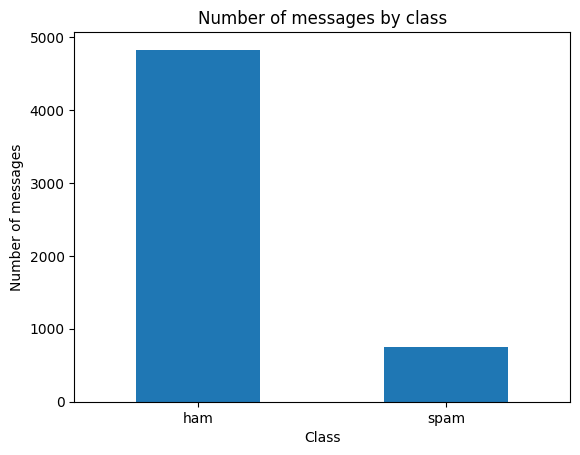

In [4]:
df["label"].value_counts().plot(kind="bar")
plt.title("Number of messages by class")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.xticks(rotation=0)
plt.show()

## 5. Split data into training and testing sets
The test set is held back until evaluation so that we can estimate how the model performs on messages it did not train on.

In [5]:
X = df["message"].astype(str)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 4457
Testing examples: 1115


## 6. Build and train the model
TF-IDF converts message text into numerical features. Logistic Regression learns patterns associated with the dataset's labels. The scikit-learn pipeline keeps text processing and classification together.

In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), max_features=20000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("Training completed.")

Training completed.


## 7. Evaluate the model
Run this cell to calculate accuracy, precision, recall, F1-score and the confusion matrix on the held-out test set. These values are generated from the downloaded dataset at runtime; they are not pre-filled or fabricated.

Test accuracy: 0.9668

Classification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.75      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



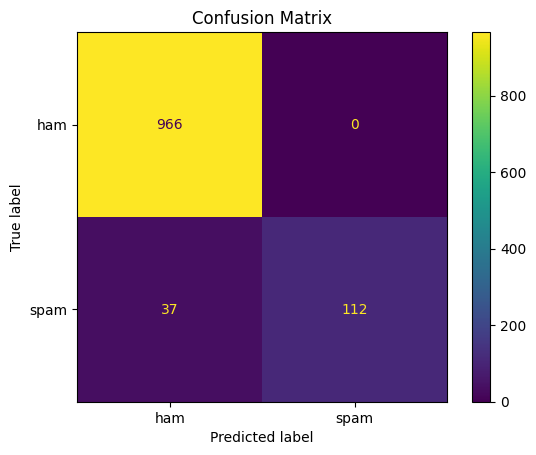

In [7]:
y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["ham", "spam"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["ham", "spam"], display_labels=["ham", "spam"], values_format="d"
)
plt.title("Confusion Matrix")
plt.show()

## 8. Test a message
Enter a message in the cell below. The output says whether the model classifies it as spam or ham. Remember: spam is not exactly the same as phishing, and an unfamiliar or malicious message may be misclassified.

In [10]:
sample_message = "Your account will be suspended. Verify your details immediately using this link."
prediction = model.predict([sample_message])[0]
print("Model classification:", prediction.upper())
print("Interpretation:", "Potentially suspicious message; verify independently." if prediction == "spam" else "Classified as ham, but this does NOT guarantee safety.")

Model classification: HAM
Interpretation: Classified as ham, but this does NOT guarantee safety.


## 9. Try your own message
Replace the text below with a message you want to test, then run the cell.

In [11]:
message_to_check = "Congratulations! You have won a prize. Call now to claim."
result = model.predict([message_to_check])[0]
print("Message:", message_to_check)
print("Predicted class:", result.upper())
if result == "spam":
    print("Caution: this message resembles spam in the training data.")
else:
    print("The model classified this as ham. Still check the sender and links carefully.")

Message: Congratulations! You have won a prize. Call now to claim.
Predicted class: SPAM
Caution: this message resembles spam in the training data.


## 10. Conclusion and limitations
- This project demonstrates a complete text-classification workflow: data loading, exploration, splitting, feature extraction, model training and evaluation.
- The dataset is an SMS spam collection, not a dedicated phishing-email dataset. Therefore the model is a learning prototype and should not be described as a validated email security product.
- Accuracy alone is not enough. False negatives (spam/phishing messages classified as ham) are especially important in security.
- Future improvement: retrain and evaluate on a labelled phishing-email dataset with clear licensing and a documented source; test on a separate real-world dataset; analyse false positives and false negatives.